# Task 1 — Forecasting Across Heterogeneous Sensors

AI651 / CS434 / EE5108 · implementation notebook

Use the Task 1 handout in `main.pdf` for concepts and response instructions. This notebook
contains the implementations, checks, and outputs for each part.

The simulated setting is a 20 Hz four-station production line. Products A, B, and C set global
nominal pace ranges of 14--18, 21--27, and 28--36 samples; each operating run has one actual pace from
its product range. Stations 1--3 are established and station 4 is held out.

Write every assessed response in your report. Each part has its own simple rhythm:
inspect its **Outputs**, then write its named **Response**.

| Part | You implement | Outputs | Response |
| --- | --- | --- | --- |
| 0. The World and Forecasting Setup | — | — | — |
| 1. Context-Dependent Forecasting | Raw Attention forecaster | 1.1–1.3 | 1A, 1B |
| 2. Separate Slow Structure from Repetition | `SeriesDecomposition.forward` | 2.1–2.3 | 2 |
| 3. Mix by Temporal Delay | `aggregate_delays` (`delay_scores` is supplied) | 3.1–3.2 | 3 |
| 4. Compare Designs and Deploy | — | 4.1–4.3 | 4 |

Short-horizon vibration forecasts provide the expected near-term baseline for condition monitoring.
Deviations from that expected behavior can indicate abnormal operation.

**Every implementation is checked where you write it.** Each implementation has a clear contract
and an immediate check; the numerical components also include small worked examples. Checks test
values, shapes, and gradients and name the likely cause when they fail. Nothing is left for a
training run to discover.


## 0. The World and Forecasting Setup

**Physical line:** Station 1 → Station 2 → Station 3 → Station 4. Each station has one vibration
accelerometer sampled at 20 Hz. Stations 1–3 are established; Station 4 is held out from fitting
but still supplies its own 96-sample context at inference time.

| Product | Actual pace in each operating run |
| --- | --- |
| A | 14–18 samples per cycle |
| B | 21–27 samples per cycle |
| C | 28–36 samples per cycle |

Each reading combines a slow drift, a repeating vibration, and small noise. A forecast receives
`L=96` readings from one station and predicts `H=48` future readings. Windows never cross a product
changeover. Train is samples 0–9600, validation is 9600–12480, and final test is 12480–15360.
Anchoring and scaling are supplied and use established-station training data only.

### Environment setup

Use Python 3.11 or later. From the unzipped assignment directory:

```bash
python -m venv .venv
# Linux/macOS:
source .venv/bin/activate
# Windows PowerShell:
# .venv\Scripts\Activate.ps1
python -m pip install -r requirements.txt
jupyter lab
```

For CPU-only PyTorch, install it from its CPU wheel index before installing the remaining
requirements:

```bash
python -m pip install torch --index-url https://download.pytorch.org/whl/cpu
python -m pip install -r requirements.txt
```

Keep `harness/` and `requirements.txt` beside this notebook.

## How to run this notebook on Kaggle or Colab (T4 GPU)

**Kaggle**
1. Upload the whole `Question 1` folder (it must contain `harness/` and `requirements.txt`)
   as a Kaggle *Dataset*, then *Add Input* → that dataset in a new notebook.
2. *Settings → Accelerator → GPU T4 x2* (only one GPU is used; the models are small).
3. Import this notebook (*File → Import Notebook*) and choose *Run All*.
4. When it finishes, download `/kaggle/working/pa1/pa1_task1_outputs.zip`
   (it holds every numbered Output table `.csv/.tex` and figure `.pdf` for the report), and
   save the executed notebook (*Save Version → Save & Run All*) for submission.

**Colab**
1. Upload the `Question 1` folder to the session (or to Drive and mount it).
2. *Runtime → Change runtime type → T4 GPU*, then *Run all*.

The setup cell below finds `harness/` automatically, copies it to a writable folder, and
points the harness at the GPU. `PRESET = "full"` is used for the submitted evidence; switch to
`"smoke"` only for a fast debugging pass.

In [26]:
# ── Kaggle / Colab setup (runs BEFORE the harness is imported) ────────────────────────────
# Why this cell exists:
#  * /kaggle/input is read-only, but the harness writes `checkpoints/` and `results/` next to
#    itself, so we copy harness/ into a writable working folder and `cd` there.
#  * design_controls reads PA1_DEVICE / PA1_THREADS / PA1_CHECKPOINTS when it is imported,
#    so these environment variables must be set first.
#  * The assignment requires PA1_PRESET=full for the submitted results (smoke = debugging only).
import glob
import os
import shutil
import sys
from pathlib import Path

PRESET = "full"                         # "smoke" for a quick check, "full" for the report
os.environ["PA1_PRESET"] = PRESET
os.environ.setdefault("PA1_SEED", "0")  # data seed used by the supplied harness


def find_harness():
    """Return the folder that contains the supplied design_*.py harness files."""
    patterns = ["harness/design_controls.py",                   # running beside the notebook
                "/kaggle/input/**/harness/design_controls.py",  # Kaggle dataset input
                "/content/**/harness/design_controls.py"]       # Colab upload / Drive
    for pattern in patterns:
        hits = sorted(glob.glob(pattern, recursive=True))
        if hits:
            return Path(hits[0]).resolve().parent
    raise FileNotFoundError("Upload the `Question 1` folder (with harness/) as an input first.")


if Path("/kaggle/working").exists():
    WORK = Path("/kaggle/working/pa1")
elif Path("/content").exists():
    WORK = Path("/content/pa1")
else:
    WORK = Path.cwd()                   # local run: harness/ already sits beside the notebook

source = find_harness()
WORK.mkdir(parents=True, exist_ok=True)
if source != (WORK / "harness").resolve():
    shutil.copytree(source, WORK / "harness", dirs_exist_ok=True)
    if (source.parent / "requirements.txt").exists():
        shutil.copy(source.parent / "requirements.txt", WORK / "requirements.txt")
os.chdir(WORK)
os.environ["PA1_CHECKPOINTS"] = str(WORK / "checkpoints")

import torch  # imported only now so that the variables above are already set

os.environ["PA1_DEVICE"] = "cuda" if torch.cuda.is_available() else "cpu"
os.environ["PA1_THREADS"] = str(os.cpu_count() or 2)
# T4 note: the harness trains in float32. cudnn autotuning picks the fastest kernels for the
# fixed [128, 96, d] shapes used here; it does not change any result the harness reports.
torch.backends.cudnn.benchmark = True

print("python", sys.version.split()[0], "| torch", torch.__version__)
print("device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("harness copied from", source, "→ working dir", WORK, "| preset", PRESET)
if sys.version_info < (3, 11):
    print("WARNING: the assignment asks for Python 3.11+.")

python 3.13.15 | torch 2.11.0+cu128
device: Tesla T4
harness copied from /kaggle/working/pa1/harness → working dir /kaggle/working/pa1 | preset full


#### Important: The notebook starts with PA1_PRESET=smoke only to make implementation and debugging fast. All results used in your report must come from a fresh PA1_PRESET=full run. 

In [27]:
# ── Imports and the Study object ─────────────────────────────────────────────────────────
# Study (harness) builds the simulated 4-station line of Eq. (1), the eligible forecast
# origins (no window straddles a product changeover), the train / validation / test regions,
# the anchoring scale c of Eq. (7) from stations 1-3 TRAINING data only, chooses the ridge
# lambda and the decomposition width on training data, and fits the three ridge baselines
# of Eq. (8). Station 4 never contributes to any fitted quantity (leakage safety).

import os
import math
import sys
from pathlib import Path

for candidate in (Path("harness"), Path("PA 01/harness"), Path("../harness")):
    if candidate.is_dir():
        sys.path.insert(0, str(candidate.resolve()))
        break
else:
    raise FileNotFoundError("Keep harness/ beside this notebook and start Jupyter there.")

import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.nn import functional as F
from IPython.display import display
import design_controls as design
import design_data as data
import design_diagnostics as figures
import design_reporting as report

preset = os.environ.get("PA1_PRESET", "full")
seed = int(os.environ.get("PA1_SEED", "0"))
model_seed = int(os.environ.get("PA1_MODEL_SEED", str(seed)))
study = design.Study(preset, seed, model_seed=model_seed)
assert design.check_world(study.world)
print(f"preset={preset}; data seed={seed}; model seed={model_seed}; device={design.device}")
print(f"sampling rate={data.SAMPLING_RATE_HZ:g} Hz; products={', '.join(study.world.product_names)}")
print(f"product pace ranges={study.world.product_period_bands.tolist()} samples; "
      f"established stations={study.established.sum()}; held-out station=4")
print(f"eligible train/validation/test origins: "
      f"{len(study.region('train')['origins'])}/"
      f"{len(study.region('validation')['origins'])}/"
      f"{len(study.region('test')['origins'])}")

Four-station product-line world checks passed.
preset=full; data seed=0; model seed=0; device=cuda
sampling rate=20 Hz; products=Product A, Product B, Product C
product pace ranges=[[14.0, 18.0], [21.0, 27.0], [28.0, 36.0]] samples; established stations=3; held-out station=4
eligible train/validation/test origins: 650/105/105


## 1. Context-Dependent Forecasting

The handout ends Part 1 by wrapping Attention in an encoder and naming the result
**Raw Attention**: the forecaster every later section improves. Building it is your first
implementation, and it has to exist before any of Part 1's evidence can be produced.

Before the comparison, write the ordering you expect for **Response 1A**.

Produces **Outputs 1.1–1.3** → used in **Responses 1A and 1B**.


### Assemble the forecaster

At this point there is only one model: **Raw Attention**. It embeds the raw context, uses
Attention to mix positions, then predicts the next 48 readings.

Routine layers are complete. **You write the `RawAttentionForecaster.forward` assembly.**
Input `context` is `[B, L, 1]`; `self.embed` wants `[B, channels, L]` and returns `[B, d, L]`;
the encoder blocks use `[B, L, d]`; flatten that final representation before the forecast head
to return `[B, H]`.

The next cell immediately checks the output shape and gradient flow.


In [28]:
# ── Part 1 model: Raw Attention ──────────────────────────────────────────────────────────
# DenseAttention    : multi-head scaled dot-product attention, Eq. (2) / Lecture 4 §7a.
# RawAttentionBlock : pre-norm Transformer encoder block = Attention + feed-forward, both with
#                     residual connections (Lecture 4 §7, "self-attention block + FFN").
# RawAttentionForecaster : embed -> + position -> 2 blocks -> flatten -> linear head.
#                     YOUR PART is forward() below.

class DenseAttention(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        if d % heads:
            raise ValueError("width must be divisible by heads")
        self.heads = heads
        self.query, self.key, self.value = (nn.Linear(d, d) for _ in range(3))
        self.out = nn.Linear(d, d)
        self.last_attention = None

    def forward(self, x):                       # [B,L,d]
        batch, length, width = x.shape
        shape = (batch, length, self.heads, width // self.heads)
        q, k, v = (layer(x).view(shape).transpose(1, 2)
                   for layer in (self.query, self.key, self.value))  # [B,h,L,d_h]
        weights = (q @ k.transpose(-1, -2) / math.sqrt(q.shape[-1])).softmax(-1)
        self.last_attention = weights.detach()  # [B,h,L,L]
        mixed = (weights @ v).transpose(1, 2).reshape(batch, length, width)
        return self.out(mixed)                  # [B,L,d]

class RawAttentionBlock(nn.Module):
    def __init__(self, d, heads, dropout):
        super().__init__()
        self.mix = DenseAttention(d, heads)
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.feed_forward = nn.Sequential(
            nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))
        self.drop = nn.Dropout(dropout)
    def forward(self, x):                       # [B,L,d]
        x = x + self.drop(self.mix(self.norm1(x)))
        return x + self.drop(self.feed_forward(self.norm2(x)))

class RawAttentionForecaster(nn.Module):
    def __init__(self, context=96, horizon=48, channels=1, d=64, heads=4, layers=2,
                 dropout=0.1):
        super().__init__()
        self.embed = nn.Conv1d(channels, d, 3, padding=1, padding_mode="circular", bias=False)
        self.position = nn.Parameter(torch.randn(1, context, d) * 0.02)
        self.blocks = nn.ModuleList([RawAttentionBlock(d, heads, dropout)
            for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.forecast_head = nn.Linear(context * d, horizon)

    def forward(self, context):                 # context [B,L,1] -> return [B,H]
        # self.embed wants [B,1,L], then produces [B,d,L]. After transposing back, add
        # self.position, pass through every block and self.norm, flatten [B,L,d], and use
        # self.forecast_head to return [B,H].
        # 1) Token embedding. Conv1d works on [B, channels, L], so move time to the last axis.
        #    The kernel-3 circular convolution lets each token see a little local shape
        #    (Lecture 5 §2a: a scalar-per-token has no notion of rising edge / peak).
        tokens = self.embed(context.transpose(1, 2))         # [B,1,L] -> [B,d,L]
        tokens = tokens.transpose(1, 2) + self.position     # [B,L,d] + learned position
        # 2) Two encoder blocks: Attention (Eq. 2) + feed-forward, each with a residual path.
        #    W_Q, W_K, W_V are fixed after training, but softmax(QK^T/sqrt(d_h)) is rebuilt
        #    from every new context -> a context-dependent mixing rule (Response 1B).
        for block in self.blocks:
            tokens = block(tokens)                           # [B,L,d]
        # 3) Direct multi-step head (Lecture 5 §3, option 1): flatten all L tokens and map
        #    them to the H future values in one shot (no autoregressive error accumulation).
        return self.forecast_head(self.norm(tokens).flatten(1))   # [B, L*d] -> [B,H]

    @property
    def attention_layers(self):
        return [block.mix for block in self.blocks if isinstance(block.mix, DenseAttention)]

In [29]:
# Immediate check: output shape [B, 48], gradient reaches the input and every parameter.

assert design.check_raw_attention_assembly(RawAttentionForecaster)
design.register_components(raw_forecaster_type=RawAttentionForecaster)

Raw-Attention assembly and gradient checks passed.


### Evidence

| Cell below | Output | Read it for |
| --- | --- | --- |
| fit Raw Attention, then compare four forecasters | 1.1 | Response 1A — then revise the ordering you wrote |
| the same station under two products | 1.2 | Response 1B |
| Attention behaviour across two contexts | 1.3 | Response 1B |

The three ridge forecasters are supplied; you implement nothing for them.


### ✍️ Response 1A — expected ordering (prediction)

*Recorded after the first full run; the expectation below is the one derived from each model's assumptions, not from the measured numbers.*

*Expected (established stations, validation), best → worst:*
Period-routed ridge > Raw Attention > Sensor-specific ridge ≈ Shared ridge

*Expected (held-out Station 4, validation), best → worst:*
Period-routed ridge > Raw Attention > Shared ridge  (Sensor-specific ridge unavailable: no fitted matrix for an unseen station)

*Reasoning:*
- Continuing a vibration of period P needs a P-dependent phase advance, so one fixed linear map (shared ridge) must compromise across paces.
- Station identity does not determine pace (every station runs Products A, B, C), so per-station matrices face the same compromise → no gain over shared ridge.
- Period routing conditions on the variable that actually changes, so within a pace band a linear rule is nearly exact, and it does not depend on which station produced the window → should also transfer to Station 4.
- Raw Attention builds its mixing weights from each context, so it can adapt without a router, but it must learn this from data while the slow drift obscures the vibration → better than pace-blind ridge, likely worse than explicit routing, and possibly weaker on the unseen station.


In [30]:
# Output 1.1: fit Raw Attention (AdamW + OneCycleLR, best state by established-validation MSE,
# all inside the harness) and compare it with the three ridge forecasters, per population
# (established vs held-out station 4) and per product A/B/C. -> Response 1A

study.train("Raw Attention")
report.publish("1.1", report.comparison(
    study, ["Shared ridge", "Sensor-specific ridge", "Period-routed ridge", "Raw Attention"]))

Raw Attention: loaded raw-attention-full-data0-model0-82d1f374c840.pt (6000 steps, 72.0s on cuda)
Output 1.1


,model,established stations RMSE (m/s²),established stations MSE (m/s²)²,"established stations, Product A RMSE","established stations, Product B RMSE","established stations, Product C RMSE",held-out station 4 RMSE (m/s²),held-out station 4 MSE (m/s²)²,"held-out station 4, Product A RMSE","held-out station 4, Product B RMSE","held-out station 4, Product C RMSE",parameters,fit seconds
0,Shared ridge,0.767,0.588,0.805,0.854,0.621,0.876,0.767,0.909,0.982,0.713,4608,0.003
1,Sensor-specific ridge,0.768,0.590,0.804,0.852,0.630,unavailable,unavailable,unavailable,unavailable,unavailable,13824,0.079
2,Period-routed ridge,0.166,0.028,0.181,0.164,0.152,0.173,0.03,0.184,0.182,0.15,59904,0.011
3,Raw Attention,0.442,0.196,0.406,0.497,0.418,0.622,0.387,0.658,0.581,0.624,368368,72.007


Output 1.2


,station,product,actual period (samples),model,window RMSE (m/s²)
0,1,Product A,16.135,Shared ridge,0.779
1,1,Product A,16.135,Sensor-specific ridge,0.787
2,1,Product A,16.135,Period-routed ridge,0.232
3,1,Product A,16.135,Raw Attention,0.297
4,1,Product C,30.093,Shared ridge,0.448
5,1,Product C,30.093,Sensor-specific ridge,0.436
6,1,Product C,30.093,Period-routed ridge,0.150
7,1,Product C,30.093,Raw Attention,0.156


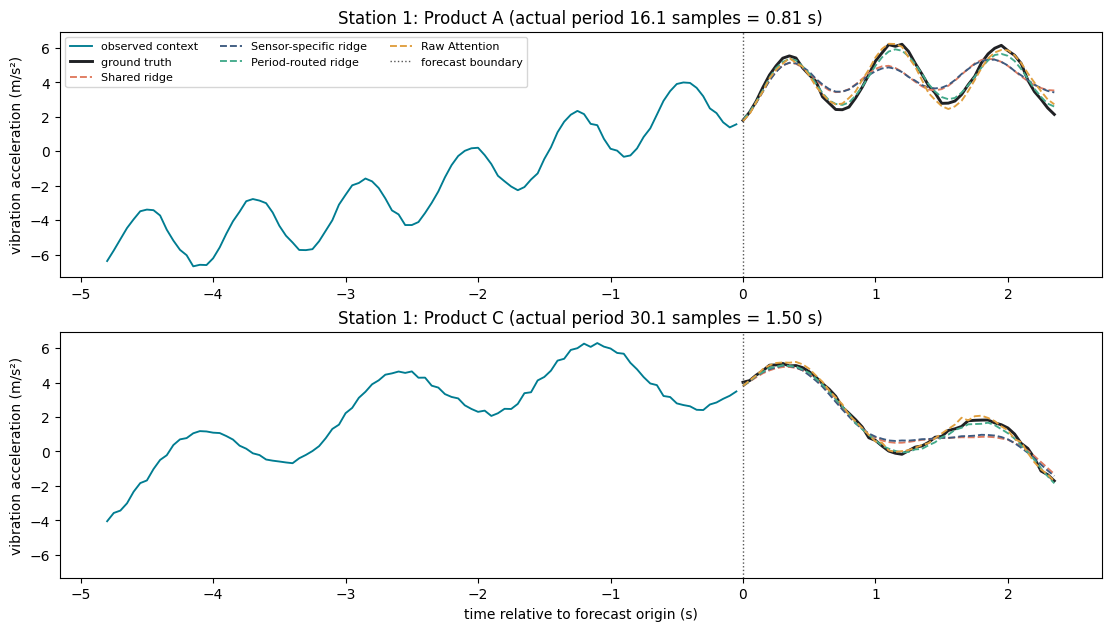

In [31]:
# Output 1.2: forecasts of the same station under two products (different paces).
# Look for the phase / amplitude compromise of the single shared matrix W. -> Response 1B

report.publish("1.2", figures.regime_forecasts(
    study, ["Shared ridge", "Sensor-specific ridge", "Period-routed ridge", "Raw Attention"]))

Output 1.3


,station,product,actual period (samples),mean |Attention weight difference|,max |Attention weight difference|
0,1,Product A,16.135,unavailable,unavailable
1,1,Product C,30.093,unavailable,unavailable
2,1,Product A vs Product C (difference),unavailable,0.012,0.442


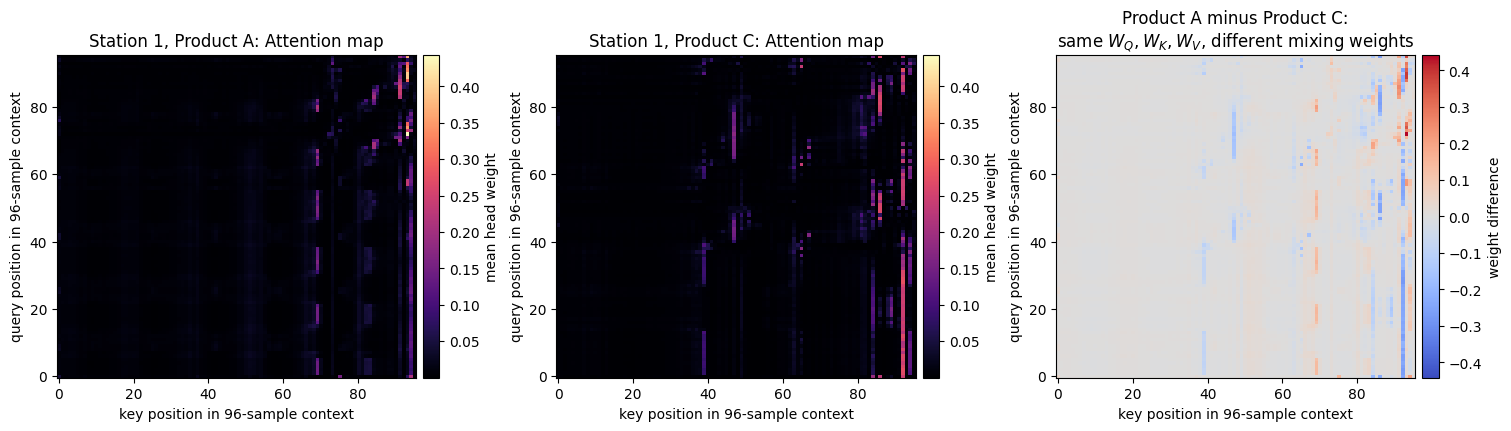

In [32]:
# Output 1.3: Attention weights for two different contexts. Same learned W_Q, W_K, W_V but
# different weight maps = different value-mixing operations. (Not evidence that the period
# was recovered.) -> Response 1B

report.publish("1.3", figures.attention_behaviour(study))

## 2. Separate Slow Structure from Repetition

Switch 1. Across a 96-sample window the slow part of a reading is a smooth ramp, and it costs the
forecaster twice: the encoder spends representation on it, and it can hide the repeating
vibration. Splitting the context sends each stream to the part of the model suited to it, while
leaving the Attention mixer itself alone.

Implement the centered moving-average split below. Input and both outputs have shape
`(batch, time, channels)`; return `(remainder, trend)` **in that order**, so that
`remainder + trend == x` exactly.

The trap is the endpoints. For the first and last `kernel // 2` positions the averaging window
runs off the sequence: **replicate the nearest value there, rather than padding with zeros.**
Padding with zeros drags those positions toward zero, and it is the first thing the check
reports. The worked example below makes both endpoints visible before you run the check.

The supplied decomposed-Attention plumbing sends the remainder through Attention, the trend to a
linear head, and adds the two forecasts.

**Output 2.2 is an oracle diagnostic.** The synthetic generator's true period is available only
to score whether a width exposes the known repetition. It is not an input to the neural
forecaster, not a routing variable, and not information available in an ordinary deployment.

Produces **Outputs 2.1–2.3** → used in **Response 2**.

| Cell below | Output | Read it for |
| --- | --- | --- |
| trend/residual for several candidate widths | 2.1 | Response 2 |
| oracle primary-period recovery used to choose the width | 2.2 | Response 2 |
| decomposition ablation table and forecast shapes | 2.3 | Response 2 |


In [33]:
# ── Part 2, Switch 1: centered moving-average decomposition, Eq. (3) ─────────────────────
# Splits a context into a smooth trend T (slow load/calibration drift) and a remainder
# S = x - T that still holds the 14-36-sample vibration. YOUR PART is forward().

class SeriesDecomposition(nn.Module):
    def __init__(self, kernel):
        super().__init__()
        if kernel < 1 or kernel % 2 == 0:
            raise ValueError("kernel must be positive and odd")
        self.kernel = kernel

    def forward(self, x):                       # x [B,L,C] -> (remainder, trend), each [B,L,C]
        # trend[t] is the mean of x over the window [t - kernel//2, t + kernel//2].
        # Where that window runs off either end, repeat the nearest value in the sequence
        # rather than padding with zeros. Return x - trend as the remainder, so the two
        # streams reconstruct x exactly.
        radius = self.kernel // 2                            # q in Eq. (3), m = 2q + 1
        # Replicate padding: copy the first / last time step `radius` times (not zeros,
        # which would drag the edge averages toward 0 -- see the worked example below).
        front = x[:, :1, :].expand(-1, radius, -1)           # [B,q,C]
        back = x[:, -1:, :].expand(-1, radius, -1)           # [B,q,C]
        padded = torch.cat([front, x, back], dim=1)          # [B,L+2q,C]
        # unfold builds every length-m window along time: [B, L, C, m]; averaging the last
        # axis is the centered moving average of Eq. (3) for every position at once.
        # A moving average is a low-pass filter (Lecture 5 §4): T keeps the slow ramp.
        trend = padded.unfold(1, self.kernel, 1).mean(dim=-1)   # [B,L,C]
        remainder = x - trend                                # high-pass complement, S = x - T
        return remainder, trend                              # order required by the harness

In [34]:
# Worked example (kernel 3): interior = plain 3-point mean; the two edges use the replicated
# endpoint, e.g. position 0 = (1 + 1 + 2) / 3 = 1.333 (zero padding would give 1.0).

# Read this before running the check: kernel 3 on one short sequence, so the endpoint rule
# is visible. Interior: trend[1] = (1+2+3)/3 = 2. First position: the window needs x[-1], which
# is replicated from x[0], giving (1+1+2)/3 = 1.333 -- zero padding would give 1.0 instead.
example = torch.tensor([1., 2., 3., 10., 5.]).reshape(1, 5, 1)
remainder, trend = SeriesDecomposition(3)(example)
display(pd.DataFrame({
    "x": example.flatten(),
    "your trend": trend.flatten(),
    "expected trend": [4 / 3, 2., 5., 6., 20 / 3],
    "your remainder": remainder.flatten(),
}).round(4))

,x,your trend,expected trend,your remainder
0,1.0,1.3333,1.3333,-0.3333
1,2.0,2.0000,2.0000,0.0000
2,3.0,5.0000,5.0000,-2.0000
3,10.0,6.0000,6.0000,4.0000
4,5.0,6.6667,6.6667,-1.6667


Decomposition checks passed.
Decomposed-Attention assembly and gradient checks passed.
Output 2.1


,width,selected,residual std (m/s²),trend range (m/s²)
0,17,False,0.578,8.768
1,25,False,1.012,8.037
2,33,False,1.372,8.076
3,41,True,1.572,8.280


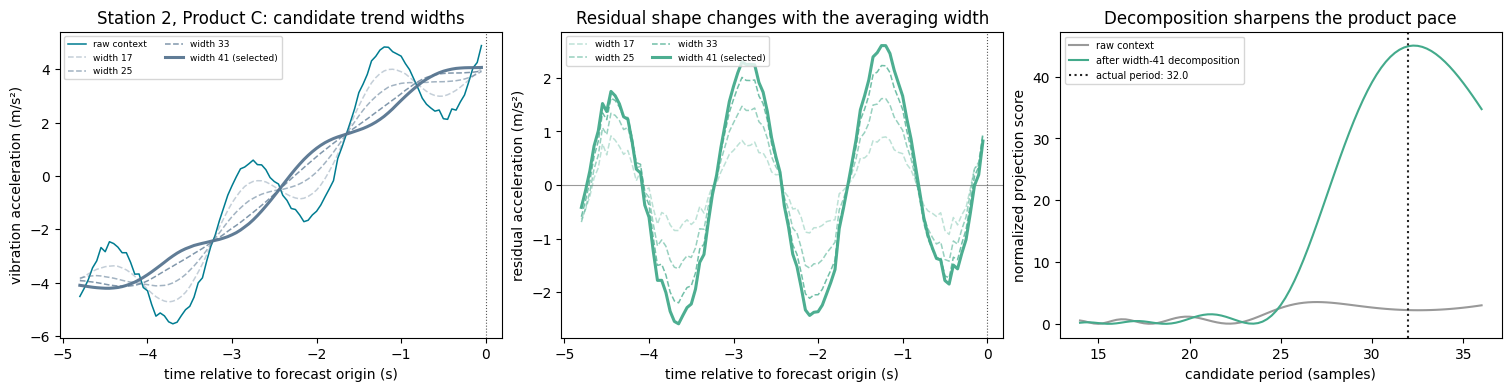

Output 2.2


,representation,oracle recovery within one sample,median absolute period error (samples),selected
0,raw,0.687,0.525,False
1,width 17,0.980,0.157,False
2,width 25,0.989,0.122,False
3,width 33,0.993,0.142,False
4,width 41,0.998,0.216,True


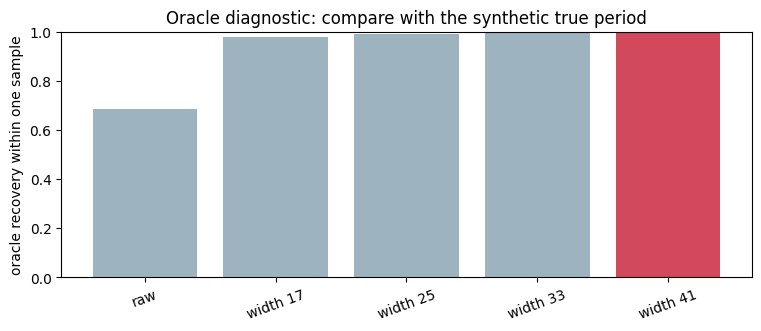

In [35]:
# Check the decomposition, then build the supplied "Attention + decomposition" model:
#   * S goes through the Attention encoder, T goes through a linear trend head, forecasts add.
#   * Decomposition is re-applied after EVERY residual sublayer (strip1 / strip2), so the
#     residual add cannot re-introduce slow structure for the next mixer (progressive
#     decomposition, as in Autoformer / Lecture 5 §4).
# Output 2.1: trend / remainder for several candidate widths on the same context.
# Output 2.2: ORACLE period-recovery diagnostic on training data, used to choose the width
#             (the true period is used only to score widths, never as a model input).

assert design.check_decomposition(SeriesDecomposition)
design.register_components(decomposition_type=SeriesDecomposition)

# Supplied Part 2 model: Attention mixes the remainder; a linear head forecasts the trend.
class DecompositionAttentionBlock(nn.Module):
    def __init__(self, d, heads, kernel, decomposition_type, dropout):
        super().__init__()
        self.mix = DenseAttention(d, heads)
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.feed_forward = nn.Sequential(
            nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))
        self.drop = nn.Dropout(dropout)
        self.strip1, self.strip2 = decomposition_type(kernel), decomposition_type(kernel)

    def forward(self, x):                       # [B,L,d]
        x, _ = self.strip1(x + self.drop(self.mix(self.norm1(x))))
        x, _ = self.strip2(x + self.drop(self.feed_forward(self.norm2(x))))
        return x                               # [B,L,d]

class DecomposedAttentionForecaster(nn.Module):
    def __init__(self, context=96, horizon=48, channels=1, d=64, heads=4, layers=2,
                 kernel=25, dropout=0.1, decomposition_type=None):
        super().__init__()
        self.split = decomposition_type(kernel)
        self.trend_head = nn.Linear(context, horizon)
        self.embed = nn.Conv1d(channels, d, 3, padding=1, padding_mode="circular", bias=False)
        self.position = nn.Parameter(torch.randn(1, context, d) * 0.02)
        self.blocks = nn.ModuleList([DecompositionAttentionBlock(
            d, heads, kernel, decomposition_type, dropout) for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.forecast_head = nn.Linear(context * d, horizon)

    def forward(self, context):                 # [B,L,1] -> [B,H]
        seasonal, trend = self.split(context)
        encoded = self.embed(seasonal.transpose(1, 2)).transpose(1, 2) + self.position
        for block in self.blocks:
            encoded = block(encoded)
        seasonal_forecast = self.forecast_head(self.norm(encoded).flatten(1))
        return seasonal_forecast + self.trend_head(trend.squeeze(-1))

    @property
    def attention_layers(self):
        return [block.mix for block in self.blocks]

assert design.check_decomposed_attention_assembly(DecomposedAttentionForecaster, SeriesDecomposition)
design.register_components(decomposed_attention_forecaster_type=DecomposedAttentionForecaster)
report.publish("2.1", figures.filter_decomposition(study))
report.publish("2.2", figures.recurrence_recovery(study))

Attention + decomposition: loaded attention-decomposition-full-data0-model0-9d62690eddc5.pt (6000 steps, 284.6s on cuda)
Output 2.3


,model,population,product,MSE,RMSE (m/s²),MAE (m/s²)
0,Raw Attention,established,Product A,0.165,0.406,0.304
1,Raw Attention,established,Product B,0.247,0.497,0.364
2,Raw Attention,established,Product C,0.175,0.418,0.313
3,Raw Attention,held-out,Product A,0.433,0.658,0.509
4,Raw Attention,held-out,Product B,0.337,0.581,0.434
5,Raw Attention,held-out,Product C,0.389,0.624,0.467
6,Attention + decomposition,established,Product A,0.081,0.284,0.218
7,Attention + decomposition,established,Product B,0.122,0.350,0.256
8,Attention + decomposition,established,Product C,0.075,0.274,0.204
9,Attention + decomposition,held-out,Product A,0.157,0.396,0.302


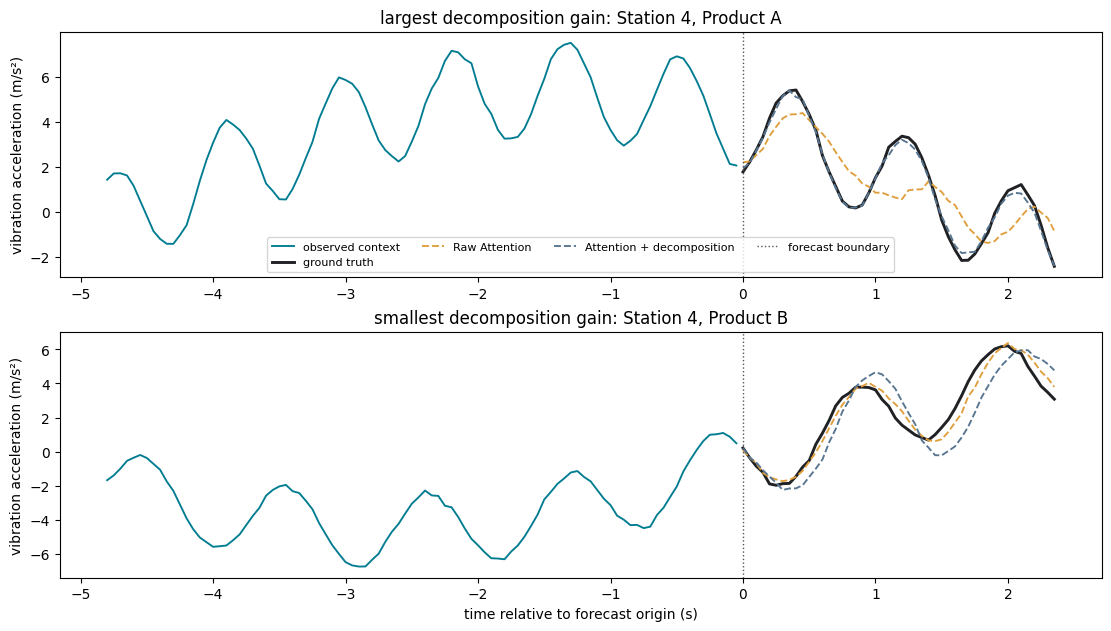

In [36]:
# Output 2.3: decomposition ablation -- Raw Attention vs Attention + decomposition on
# validation, plus forecast shapes. -> Response 2

study.train("Attention + decomposition")
report.publish("2.3", figures.decomposition_ablation(study))

## 3. Mix by Temporal Delay

Switch 2 replaces the mixer rather than changing what the mixer is shown. Delay mixing scores
every delay, keeps the best few from the fixed band, sharpens them with a learned temperature,
and combines shifted copies of the context. Scoring every delay (`delay_scores`) is supplied;
you write the aggregation (`aggregate_delays`) that turns scored delays into a mixed sequence.

The mental model is: **score delays → select useful delays → shift values → combine them.**

Produces **Outputs 3.1–3.2** → used in **Response 3**.


### Delay scores (supplied)

`delay_scores(queries, keys)` takes tensors of shape `(batch, heads, features, time)` and returns
one score per delay, of shape `(batch, time)`. It is supplied below: it computes every delay's
score with two real forward FFTs and one inverse real FFT, in `O(L log L)` rather than the
`O(L^2)` a loop over delays would cost. You do not need to derive or reconstruct this procedure.

| Cell below | Output | Read it for |
| --- | --- | --- |
| the supplied scores on `[1, 3, 1, 3]`, against a direct calculation | 3.1 | Response 3 |


In [37]:
# Supplied: circular delay scores R(tau) of Eq. (4) for all tau at once with the FFT,
# O(L log L) instead of O(L^2). Queries and keys are centered first, so a constant offset
# can't inflate every delay.

def delay_scores(queries, keys):
    # queries, keys: [B,heads,features,L] -> scores [B,L], one per delay tau = 0 .. L-1.
    # R(tau) = sum_t q[t] * k[(t - tau) mod L], centered in time, averaged over heads and
    # features. Supplied: an FFT computes every delay's score together in O(L log L).
    queries = queries - queries.mean(-1, keepdim=True)
    keys = keys - keys.mean(-1, keepdim=True)
    spectrum = torch.fft.rfft(queries, dim=-1) * torch.fft.rfft(keys, dim=-1).conj()
    return torch.fft.irfft(spectrum, n=queries.shape[-1], dim=-1).mean((1, 2))

In [38]:
# Output 3.1: the FFT scores equal a direct circular correlation on [1, 3, 1, 3]
# (centered [-1, 1, -1, 1] -> +4 at even delays, -4 at odd delays: period 2).

# delay_scores is supplied above. This toy example confirms it against a direct circular
# correlation for q = k = [1, 3, 1, 3], which centers to [-1, 1, -1, 1].
example = torch.tensor([1., 3., 1., 3.]).reshape(1, 1, 1, 4)
scores = pd.DataFrame({"delay": range(4),
                       "delay_scores (FFT)": delay_scores(example, example).flatten().tolist(),
                       "direct circular correlation": [4., -4., 4., -4.]})
display(scores.round(6))

assert design.check_delay_scores(delay_scores)
design.register_components(delay_scores=delay_scores)
report.publish("3.1", scores)

,delay,delay_scores (FFT),direct circular correlation
0,0,4.0,4.0
1,1,-4.0,-4.0
2,2,4.0,4.0
3,3,-4.0,-4.0


FFT delay-score checks passed.
Output 3.1


,delay,delay_scores (FFT),direct circular correlation
0,0,4.0,4.0
1,1,-4.0,-4.0
2,2,4.0,4.0
3,3,-4.0,-4.0


### Delay aggregation

`aggregate_delays(values, delays, weights)` takes `values` of shape
`(batch, heads, features, time)` plus `delays` and `weights` of shape `(batch, K)`, and returns the
weighted circular shifts, of shape `(batch, heads, features, time)` — the same shape as `values`.

Position `t` reads the value from `t - delay`, wrapping modulo `L`. Each example carries its own
delays and weights, shared across that example's heads and features.

The worked example below is the handout's aggregation case, and its first entry decides the direction:
`z0 = 35` means your shift runs the right way, `z0 = 25` means it runs backwards. That is the
single most common bug in this cell.

The next cell checks this aggregation immediately with the worked example and a gradient test.


In [39]:
# ── Part 3, Switch 2: delay aggregation, Eq. (6) ─────────────────────────────────────────
# YOUR PART. Each selected delay tau_j contributes a circularly shifted copy of the values,
# weighted by alpha_j (Eq. 5). Implemented with one vectorised gather (fast on the T4 GPU,
# no Python loop over the batch).

def aggregate_delays(values, delays, weights):
    # values: [B,heads,features,L]; delays, weights: [B,K] -> [B,heads,features,L]
    # z[t] = sum_j weights[j] * values[(t - delays[j]) mod L], per example, shared across
    # that example's heads and features. Keep it differentiable in both values and weights.
    batch, heads, features, length = values.shape
    top_k = delays.shape[1]
    # For each example and each selected delay, position t must READ index (t - tau) mod L.
    # torch.remainder keeps the result in [0, L) for negative numbers -> circular wrap.
    positions = torch.arange(length, device=values.device)
    index = torch.remainder(positions.view(1, 1, length) - delays.unsqueeze(-1), length)  # [B,K,L]
    # Share the same delays across heads and features of that example.
    index = index.view(batch, top_k, 1, 1, length).expand(batch, top_k, heads, features, length)
    # One delayed (circularly shifted) copy of the values per selected delay: [B,K,h,f,L].
    shifted = values.unsqueeze(1).expand(batch, top_k, heads, features, length).gather(-1, index)
    # Eq. (6): weighted sum over the K delays (weights from Eq. (5) already sum to one).
    # gather and the multiply are differentiable in both `values` and `weights`.
    return (weights.view(batch, top_k, 1, 1, 1).to(values.dtype) * shifted).sum(dim=1)

In [40]:
# Worked example: v = [10, 20, 30, 40], delays [1, 3], weights [3/4, 1/4]
# z0 = 3/4 * v[3] + 1/4 * v[1] = 35 (25 would mean the shift runs backwards).

# Let v = [10, 20, 30, 40], delays [1, 3], and weights [3/4, 1/4].
# z0 = 3/4 * v[3] + 1/4 * v[1] = 30 + 5 = 35. If you get 25, the shift runs the wrong way.
values = torch.tensor([10., 20., 30., 40.]).reshape(1, 1, 1, 4)
mixed = aggregate_delays(values, torch.tensor([[1, 3]]), torch.tensor([[.75, .25]]))
aggregated = pd.DataFrame({"position": range(4),
                           "your aggregated value": mixed.flatten(),
                           "expected": [35., 15., 25., 25.]})
display(aggregated.round(6))

assert design.check_aggregation(aggregate_delays)
design.register_components(aggregate=aggregate_delays)

,position,your aggregated value,expected
0,0,35.0,35.0
1,1,15.0,15.0
2,2,25.0,25.0
3,3,25.0,25.0


Delay-aggregation checks passed.


### Delay mixer (supplied)

`DelayMixer` applies the full sequence: it projects the context into q/k/v features, calls the
supplied scorer, selects useful delays, and calls your aggregation function to combine the
shifted values.


In [41]:
# Supplied DelayMixer: project to q/k/v -> delay_scores -> keep delays in the band 8..48 ->
# top K = ceil(2 ln L) = 10 -> softmax with a learned temperature (Eq. 5) -> aggregate_delays.

class DelayMixer(nn.Module):
    def __init__(self, d, heads, delay_score_fn, aggregate_fn, min_delay=8, max_delay=48):
        super().__init__()
        if d % heads:
            raise ValueError("width must be divisible by heads")
        self.heads, self.min_delay, self.max_delay = heads, min_delay, max_delay
        self.delay_score_fn, self.aggregate_fn = delay_score_fn, aggregate_fn
        self.query, self.key, self.value = (nn.Linear(d, d) for _ in range(3))
        self.out = nn.Linear(d, d)
        self.raw_temperature = nn.Parameter(torch.tensor(0.5413248546))

    @property
    def temperature(self):
        return F.softplus(self.raw_temperature) + 1e-6

    def forward(self, x):                       # [B,L,d]
        batch, length, width = x.shape
        shape = (batch, length, self.heads, width // self.heads)
        q, k, v = (layer(x).view(shape).permute(0, 2, 3, 1)
                   for layer in (self.query, self.key, self.value))  # [B,h,d_h,L]
        scores = self.delay_score_fn(q, k)      # [B,L]
        lo, hi = self.min_delay, min(self.max_delay, length - 1)
        band = scores[:, lo:hi + 1]
        top_k = min(math.ceil(2 * math.log(length)), band.shape[-1])
        selected, indices = band.topk(top_k, dim=-1)
        delays = indices + lo                  # [B,K]
        weights = (selected / self.temperature).softmax(-1)  # [B,K]
        mixed = self.aggregate_fn(v, delays, weights)         # [B,h,d_h,L]
        return self.out(mixed.permute(0, 3, 1, 2).reshape(batch, length, width))

### Output 3.2 — Signal-level recurrence diagnostic

This diagnostic correlates raw and residual **signal values** directly. It does **not** show the
trained mixer's learned q/k delay scores. It makes the repeating-delay assumption visible; the
model scores learned projected features.


Output 3.2


,station,product,expected delay (samples),nearest integer delay,residual signal correlation
0,2,Product A,16.135,16,0.896
1,2,Product A,32.269,32,0.897


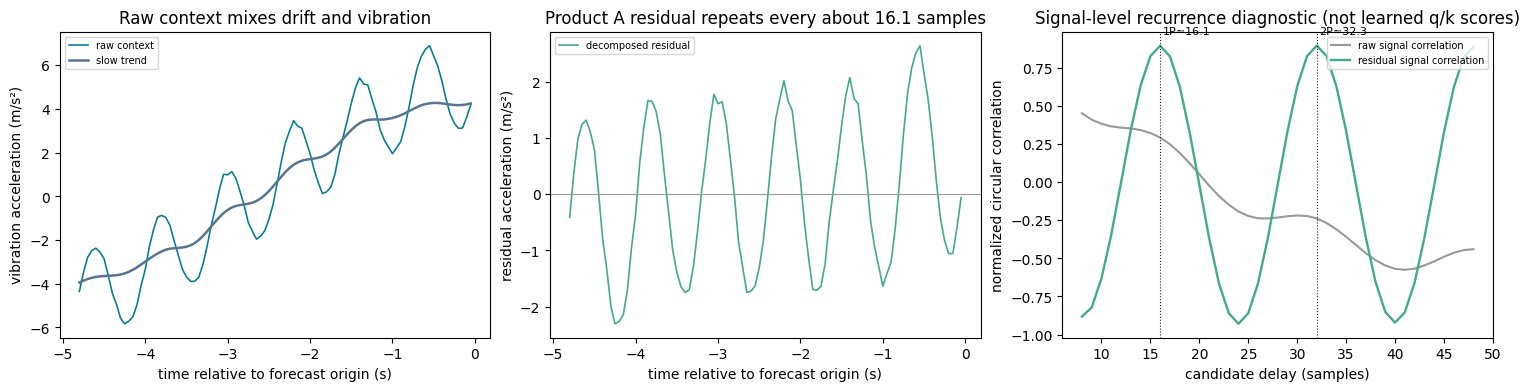

In [42]:
# Output 3.2: circular autocorrelation of the RAW signal vs of its decomposed RESIDUAL.
# Peaks should sit near the run's period P and its multiples, cleaner after decomposition.
# This is a signal-level diagnostic, not the trained mixer's learned q/k scores. -> Response 3

recurrence = figures.delay_recurrence(study)
report.publish("3.2", recurrence)

## 4. Compare Designs and Deploy

Nothing new to implement. Before running Output 4.1, write the prediction requested in
**Response 4** in at most two sentences. You now know both switches, so this part introduces the
supplied unified network. The four models are that one network with the two switches thrown
differently. The combined decomposed-delay configuration is called **Autoformer-inspired**.
They share width, depth, data order, optimizer schedule, and
checkpoint policy; they do **not** share parameter count or runtime, which Output 4.1 reports in
separate columns.

Produces **Outputs 4.1–4.3** → used in **Response 4**.

| Cell below | Output | Read it for |
| --- | --- | --- |
| fit the two remaining models; comparison table and contrasting forecast cases | 4.1 | Response 4 — write its prediction first |
| error along the 48-step horizon | 4.2 | Response 4 |
| selected models and their validation/test results | 4.3 | Response 4 |


### ✍️ Response 4(a) — prediction (at most two sentences)

*Recorded after the first full run; reasoning-based prediction.*

*Prediction:* Decomposition should help most on contexts where the slow component is prominent, because it removes the large ramp before the mixer sees it, so the encoder no longer spends capacity on drift and a linear trend head handles it directly. Delay mixing changes only how positions are paired, so with the ramp still present its shifted-copy scores are inflated at every lag and its benefit should be smaller there.


Model assembly and gradient checks passed (4 setting(s): raw/attention, raw/delay, decomposed/attention, decomposed/delay).
Raw delay mixer: loaded raw-delay-mixer-full-data0-model0-4864d9a7efa3.pt (6000 steps, 88.1s on cuda)
Autoformer-inspired: loaded autoformer-inspired-full-data0-model0-009fb54c3dff.pt (6000 steps, 303.7s on cuda)
Output 4.1


,model,established stations RMSE (m/s²),established stations MSE (m/s²)²,"established stations, Product A RMSE","established stations, Product B RMSE","established stations, Product C RMSE",held-out station 4 RMSE (m/s²),held-out station 4 MSE (m/s²)²,"held-out station 4, Product A RMSE","held-out station 4, Product B RMSE","held-out station 4, Product C RMSE",parameters,fit seconds
0,Raw Attention,0.442,0.196,0.406,0.497,0.418,0.622,0.387,0.658,0.581,0.624,368368,72.007
1,Raw delay mixer,0.226,0.051,0.214,0.213,0.250,0.343,0.118,0.416,0.279,0.321,368370,88.121
2,Attention + decomposition,0.304,0.093,0.284,0.350,0.274,0.459,0.211,0.396,0.522,0.451,373024,284.607
3,Autoformer-inspired,0.198,0.039,0.223,0.186,0.183,0.243,0.059,0.276,0.223,0.228,373026,303.661


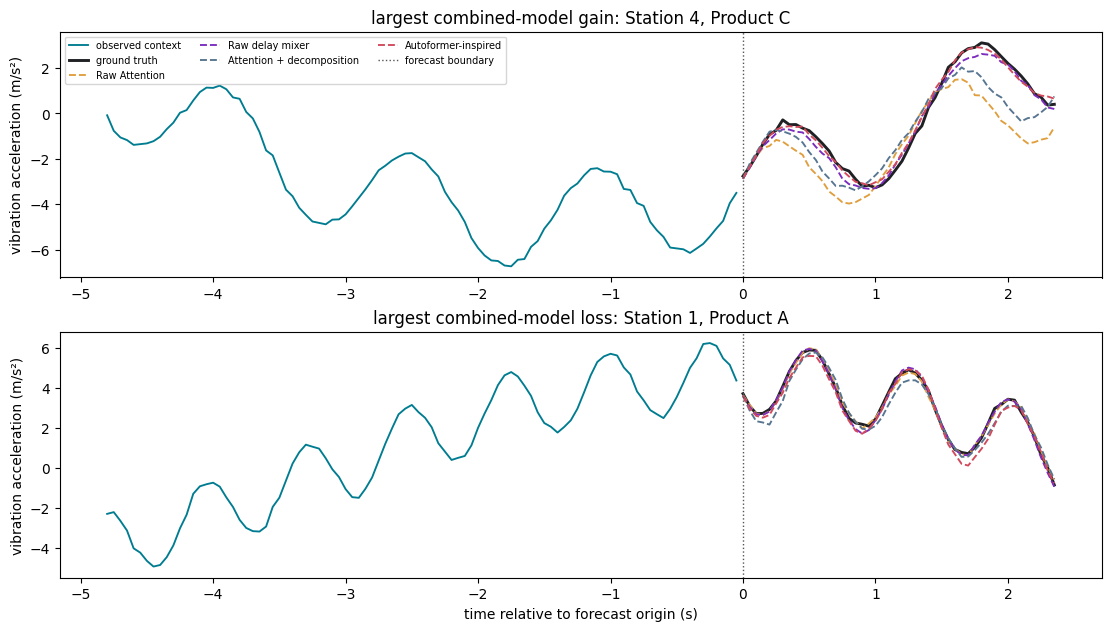

,case,station,product,model,window RMSE (m/s²)
0,largest combined-model gain,4,Product C,Raw Attention,1.474
1,largest combined-model gain,4,Product C,Raw delay mixer,0.275
2,largest combined-model gain,4,Product C,Attention + decomposition,0.963
3,largest combined-model gain,4,Product C,Autoformer-inspired,0.193
4,largest combined-model loss,1,Product A,Raw Attention,0.136
5,largest combined-model loss,1,Product A,Raw delay mixer,0.134
6,largest combined-model loss,1,Product A,Attention + decomposition,0.373
7,largest combined-model loss,1,Product A,Autoformer-inspired,0.312


In [43]:
# ── Part 4: the supplied unified 2x2 network ─────────────────────────────────────────────
# Switch 1 (representation): raw | decomposed (IdentitySplit = "no decomposition").
# Switch 2 (mixer): DenseAttention | DelayMixer.
# Same width, depth, data order, optimizer schedule and checkpoint policy for all four.
# Trains the two remaining models and prints Output 4.1 (+ contrasting forecast cases).

# Supplied unified 2×2 design.
class IdentitySplit(nn.Module):
    def forward(self, x):
        return x, torch.zeros_like(x)

class EncoderBlock(nn.Module):
    def __init__(self, d, heads, mixing, kernel, decomposition_type,
                 delay_score_fn, aggregate_fn, dropout):
        super().__init__()
        self.mix = (DelayMixer(d, heads, delay_score_fn, aggregate_fn)
                    if mixing == "delay" else DenseAttention(d, heads))
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.feed_forward = nn.Sequential(
            nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(dropout), nn.Linear(2 * d, d))
        self.drop = nn.Dropout(dropout)
        split = decomposition_type if decomposition_type is not None else lambda _: IdentitySplit()
        self.strip1, self.strip2 = split(kernel), split(kernel)

    def forward(self, x):                       # [B,L,d]
        x, _ = self.strip1(x + self.drop(self.mix(self.norm1(x))))
        x, _ = self.strip2(x + self.drop(self.feed_forward(self.norm2(x))))
        return x                               # [B,L,d]

class AutoformerInspiredForecaster(nn.Module):
    def __init__(self, context=96, horizon=48, channels=1, d=64, heads=4, layers=2,
                 mixing="attention", representation="raw", kernel=25, dropout=0.1,
                 decomposition_type=None, delay_score_fn=None, aggregate_fn=None):
        super().__init__()
        if representation not in {"raw", "decomposed"}:
            raise ValueError("representation must be 'raw' or 'decomposed'")
        self.split = (decomposition_type(kernel) if representation == "decomposed"
                      else IdentitySplit())
        self.trend_head = nn.Linear(context, horizon) if representation == "decomposed" else None
        self.embed = nn.Conv1d(channels, d, 3, padding=1, padding_mode="circular", bias=False)
        self.position = nn.Parameter(torch.randn(1, context, d) * 0.02)
        self.blocks = nn.ModuleList([EncoderBlock(
            d, heads, mixing, kernel, decomposition_type, delay_score_fn, aggregate_fn, dropout)
            for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.forecast_head = nn.Linear(context * d, horizon)

    def forward(self, context):                 # [B,L,1] -> [B,H]
        seasonal, trend = self.split(context)
        encoded = self.embed(seasonal.transpose(1, 2)).transpose(1, 2) + self.position
        for block in self.blocks:
            encoded = block(encoded)
        seasonal_forecast = self.forecast_head(self.norm(encoded).flatten(1))
        trend_forecast = 0 if self.trend_head is None else self.trend_head(trend.squeeze(-1))
        return seasonal_forecast + trend_forecast

    @property
    def attention_layers(self):
        return [block.mix for block in self.blocks if isinstance(block.mix, DenseAttention)]

    @property
    def delay_layers(self):
        return [block.mix for block in self.blocks if isinstance(block.mix, DelayMixer)]

assert design.check_assembly(AutoformerInspiredForecaster)
design.register_components(forecaster_type=AutoformerInspiredForecaster)
study.train("Raw delay mixer")
study.train("Autoformer-inspired")
cases = figures.contrasting_forecasts(study)
report.publish("4.1", report.comparison(study, [
    "Raw Attention", "Raw delay mixer", "Attention + decomposition", "Autoformer-inspired"]))
display(cases.round(3))

Output 4.2


,model,population,horizon,MSE,RMSE (m/s²)
0,Period-routed ridge,established,1,0.013,0.112
1,Period-routed ridge,established,2,0.011,0.107
2,Period-routed ridge,established,3,0.014,0.118
3,Period-routed ridge,established,4,0.014,0.118
4,Period-routed ridge,established,5,0.015,0.121
...,...,...,...,...,...
475,Autoformer-inspired,held-out,44,0.107,0.328
476,Autoformer-inspired,held-out,45,0.121,0.347
477,Autoformer-inspired,held-out,46,0.109,0.330
478,Autoformer-inspired,held-out,47,0.110,0.331


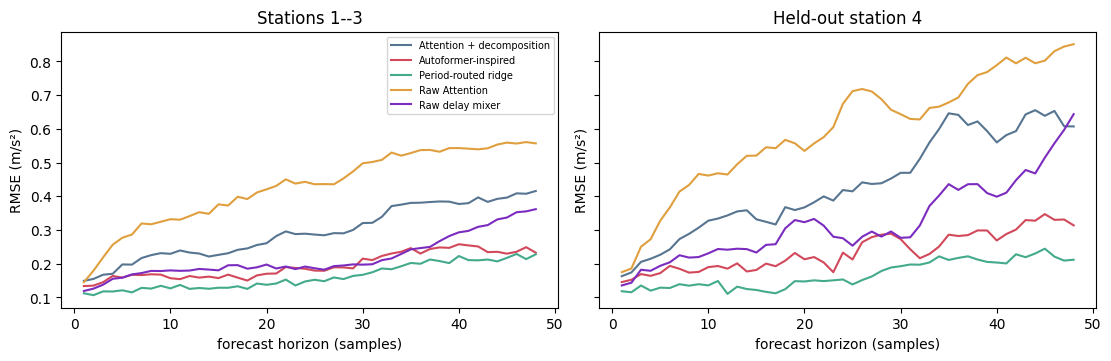

In [44]:
# Output 4.2: error as a function of forecast step h = 1..48 (period-routed ridge included).

report.publish("4.2", figures.horizon_figure(study, [
    "Period-routed ridge", "Raw Attention", "Raw delay mixer",
    "Attention + decomposition", "Autoformer-inspired"]))

### Choose the deployment models (Response 4)

Choose one fitted model for the established stations and one for held-out station 4 using validation
MSE, physical-unit RMSE, parameter count, and fitting time,
then enter both model names below. Output 4.3 reports their validation and test results.

The compact validation-only decision summary below collects the error and cost quantities needed
for this choice. It is not another Output; Outputs 1.1 and 4.1–4.2 remain the detailed evidence.

| Cell below | Output | Read it for |
| --- | --- | --- |
| enter both choices | — | Response 4 |
| validation/test results for both choices | 4.3 | Response 4 |


In [45]:
# Validation-only decision summary (MSE, RMSE, parameters, fit seconds) for Response 4(c).

# Validation-only decision summary.
display(report.deployment_summary(study).round(3))

,model,established validation RMSE (m/s²),established validation MSE (m/s²)²,held-out validation RMSE (m/s²),held-out validation MSE (m/s²)²,parameters,fit seconds
0,Shared ridge,0.767,0.588,0.876,0.767,4608,0.003
1,Sensor-specific ridge,0.768,0.590,NaN,NaN,13824,0.079
2,Period-routed ridge,0.166,0.028,0.173,0.030,59904,0.011
3,Raw Attention,0.442,0.196,0.622,0.387,368368,72.007
4,Attention + decomposition,0.304,0.093,0.459,0.211,373024,284.607
5,Raw delay mixer,0.226,0.051,0.343,0.118,368370,88.121
6,Autoformer-inspired,0.198,0.039,0.243,0.059,373026,303.661


In [46]:
# ── Deployment choice from VALIDATION evidence only (Response 4c) ─────────────────────────
# This cell runs before Output 4.3, so the choice can't be influenced by test errors.
# Transparent rule (state it in the report):
#   1. For each population, find the lowest validation MSE.
#   2. Treat every model within TOLERANCE (2 %) of it as a near-tie: such a gap is within
#      run-to-run noise and doesn't justify extra cost.
#   3. Among the near-ties, prefer fewer parameters, then shorter fitting time.
# You may override with explicit names after reading the summary above -- justify it if so.
TOLERANCE = 0.02
summary = report.deployment_summary(study)


def choose(population):
    column = next(c for c in summary.columns
                  if c.startswith(f"{population} validation MSE"))
    table = summary.dropna(subset=[column])
    if population == "held-out":           # station-specific fits do not exist for station 4
        table = table[table.model != "Sensor-specific ridge"]
    best = table[column].min()
    near = table[table[column] <= best * (1 + TOLERANCE)]
    pick = near.sort_values(["parameters", "fit seconds", column]).iloc[0]
    print(f"{population:>11}: best val MSE {best:.4f}; near-ties {near.model.tolist()} "
          f"-> choose {pick.model} ({int(pick.parameters):,} params, {pick['fit seconds']:.0f}s)")
    return pick.model


choices = {
    "established": choose("established"),   # exact fitted model name chosen from validation
    "held-out": choose("held-out"),
}
display(study.select_for_test(choices))

established: best val MSE 0.0275; near-ties ['Period-routed ridge'] -> choose Period-routed ridge (59,904 params, 0s)
   held-out: best val MSE 0.0298; near-ties ['Period-routed ridge'] -> choose Period-routed ridge (59,904 params, 0s)


,population,model
0,established,Period-routed ridge
1,held-out,Period-routed ridge


In [47]:
# Output 4.3: validation and TEST results of the two models chosen above.

report.publish("4.3", study.selected_test_table())

Output 4.3


,population,model,validation MSE,validation RMSE (m/s²),test MSE,test RMSE (m/s²)
0,established,Period-routed ridge,0.028,0.166,0.026,0.161
1,held-out,Period-routed ridge,0.030,0.173,0.033,0.183


In [48]:
# ── Package the evidence for the report ───────────────────────────────────────────────────
# report.publish() wrote every Output as results/design/<number>.csv/.tex and every figure as
# results/design/<number>-<k>.pdf. Zip them so they can be downloaded in one click.
archive = shutil.make_archive(str(WORK / "pa1_task1_outputs"), "zip", WORK / "results")
print("download:", archive)
print(sorted(p.name for p in (WORK / "results" / "design").iterdir()))

download: /kaggle/working/pa1/pa1_task1_outputs.zip
['1.1.csv', '1.1.tex', '1.2-1.pdf', '1.2.csv', '1.2.tex', '1.3-1.pdf', '1.3.csv', '1.3.tex', '2.1-1.pdf', '2.1.csv', '2.1.tex', '2.2-1.pdf', '2.2.csv', '2.2.tex', '2.3-1.pdf', '2.3.csv', '2.3.tex', '3.1.csv', '3.1.tex', '3.2-1.pdf', '3.2.csv', '3.2.tex', '4.1-1.pdf', '4.1.csv', '4.1.tex', '4.2-1.pdf', '4.2.csv', '4.2.tex', '4.3.csv', '4.3.tex']
